# L2 step 2 · Train the 3B, as option (b) or option (c) (GPU T4 ×2)

Task **L2** (roadmap), the distilled 3B for objective **O4**: a 3B model of about 6 GB that answers the six benchmark tasks, taught by our fine-tuned 7B. Decided 8 Nov: train two 3Bs and keep the better one by the rule in roadmap L2, fixed before any run. This one notebook trains either one, set by `MODE` in Cell 2.

**Changed on 19 Nov, after step 2b**
- The first run of (c) (account 1, 18 Nov) learned nothing. In half precision, about 1.2% of examples overflow, so every global batch of 256 held a NaN, and every update was skipped. Its log stays on Kaggle, in that version's Logs tab.
- Step 2b ([results](L2-step2-results/fp16-diagnostic/L2S2b/README.md)) found that all of them overflow at one layer: the last block of the 3B's vision part, `model.visual.blocks.31.mlp.down_proj`, whose outputs reach 64,352 against half precision's limit of 65,504.
- Keeping that one layer in full precision removed every NaN with no loss of speed and kept the loss within 0.0017 of full precision. All 8 of its test training steps were real updates.
- So the code has three changes, and nothing else:
  1. **The fix:** that layer runs in full precision (fp32, autocast off), as step 2b tested it, and the 4-bit layers keep the compute precision they were given.
  2. **Faster image finding:** each image folder is listed once instead of each file checked. In step 2b that took 13 s instead of 33 min per session. Step 2's own counts are still asserted.
  3. **One warning removed:** the per-step losses are logged with `.detach()`.
- **Before the first full run, the failed run's checkpoint must be gone from Hugging Face:** `c/checkpoints/checkpoint-10`, or the whole repository, which Cell 2 re-creates. Otherwise Cell 2 would resume from it. In the full run, Cell 2 must print `Starting fresh`.

**The two 3Bs**
- **Both:**
  - `Qwen/Qwen2.5-VL-3B-Instruct`, held in 4-bit, with a new LoRA adapter (rank 64, alpha 16, dropout 0.05) on the language model only.
  - Otherwise the 7B's recipe (the DisasterM3 paper's Appendix B.3, as L0 step 2 ran it on today's Kaggle):
    - AdamW 8-bit, lr 2e-4, betas 0.9 / 0.95;
    - cosine schedule with 3% warmup, weight decay 0.01, clipping 1.0;
    - a global batch of 256 (1 × 128 accumulation × 2 GPUs), one epoch.
  - Images at most 768 × 28 × 28 pixels, and the loss on the answer tokens only.
  - The 501 held-out after-photos (2,732 entries) are left out of both, so **53,032 training entries**.
- **(b) soft labels** (`MODE = "b"`): every answer is the dataset's label. On the 38,271 checkable entries the loss is 0.5 × cross-entropy on the label + 0.5 × the match to the 7B's top-20 spread (L2 step 1b's soft labels, renormalised over the 20, temperature 1). Captions and restoration advice use the label loss only.
- **(c) the options rerun** (`MODE = "c"`): L2 step 1's data, plus L2 step 1c's kept answers in the benchmark's format, with the options and a letter as the answer. L2 step 1's data is the new 7B's 1,079 checked-correct answers on training photos, and labels elsewhere. Cross-entropy only.

**Checks in the run**
- The data counts must match the ones fixed on 8 Nov, and no held-out entry may be trained on.
- **(b):** every soft label must belong to a training entry. At each answer token, the 3B's target token must equal the token the 7B's spread was computed for; tokens that don't match get no soft loss and are counted, and above 1% the run stops.
- The adapter must sit on exactly the 7 projections of each of the 36 language-model layers, with the parameter count those layers give.
- **Since 19 Nov:** step 2b's layer must be found exactly once and run in fp32, or the run stops.

**Expectation**
- **Fixed before the run (8 Nov), with no number:** the loss should start near the 7B's first training (about 0.5–1.2 on answer tokens) and fall. In (b), the soft loss stays above the label loss, since the 7B's spread is wider than one token. The held-out scoring (step 3) judges the two 3Bs by the rule.
- **Since 19 Nov:** `grad_norm` stays finite, and the learning rate leaves 0 within the first steps, as in step 2b.
- **Time,** from the failed run: about 912 s per optimizer step, so one epoch of 211 steps takes about 53 h. That's 5 sessions of 10.5 h, each continuing from the last checkpoint.

**How to run on Kaggle** (option A, chosen 19 Nov: both 3Bs, one full epoch each)
- **(c) runs on account 1, all sessions.**
- **(b) runs on accounts 2 and 3, taking turns.** Any session can run on either account, because it continues from the latest checkpoint on Hugging Face. Never run two sessions of the same mode at once.
1. **Settings:** GPU **T4 x2**, internet ON. Secret `HF_TOKEN` (AbrarAlam, **write**): checkpoints go to the private repo `AbrarAlam/disasterm3-qwen25vl3b-l2`, under `b/` or `c/`.
2. **Inputs:** `abrarmohammedtanzim/disasterm3-mirror`, plus:
   - for MODE b, the complete output of `l2-step1b-soft-labels` (account 3's notebook; share it with account 2 to use it there);
   - for MODE c, the outputs of `l2-step1-new-teacher` and `l2-step1c-options-rerun`.
3. **Smoke test:** set `MODE` in Cell 2, then Run All once with `SMOKE_TEST = True` (16 examples, 2 optimizer steps). Check the ✓ lines, including `✓ Step 2b's fix`, and Cell 5's losses, peak memory and projected hours. Then set `SMOKE_TEST = False` and Save & Run All.
4. **Later sessions:** after 10.5 h of training it saves, pushes and stops. Run it again with the same settings, and Cell 2 restores the latest checkpoint from Hugging Face. When training is complete, the adapter goes to `{MODE}/final`, where steps 3 and 4 read it.
5. **Outputs** in `/kaggle/working/L2S2-{MODE}/`: `config.json`, `train.py`, `train_summary.json`, `loss_curve.png`, `README.md`.

In [1]:
# ── Cell 1: Environment: Kaggle's torch and transformers, plus current peft and bitsandbytes (as L0 step 2) ──
import importlib.metadata as _md
import subprocess
import sys

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "peft", "bitsandbytes"], check=True)

def _version(pkg):
    try:
        return _md.version(pkg)
    except _md.PackageNotFoundError:
        return "0"

assert int(_version("transformers").split(".")[0]) >= 5, "written for transformers 5 (Kaggle's 5.16 and later)"

import torch
VERSIONS = {p: _version(p) for p in ("torch", "transformers", "peft", "bitsandbytes", "accelerate")}
print(f"✓ {VERSIONS}, python {sys.version.split()[0]}")
print(f"  GPUs: {[torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())]}")


✓ {'torch': '2.11.0+cu130', 'transformers': '5.20.2', 'peft': '0.22.0', 'bitsandbytes': '0.50.2', 'accelerate': '1.15.0'}, python 3.13.16
  GPUs: ['Tesla T4', 'Tesla T4']


In [2]:
# ── Cell 2: Configuration, Hugging Face access, the inputs, the base model in the cache, the latest checkpoint ──
import glob
import json
import os
import shutil
from pathlib import Path

from huggingface_hub import HfApi, snapshot_download

MODE = "c"                     # "b" = soft labels (account 3); "c" = the options rerun (account 1)
SMOKE_TEST = False             # True = 16 examples, 2 optimizer steps: memory and time check
assert MODE in ("b", "c")
WORK = Path(f"/kaggle/working/L2S2-{MODE}")

def one(pattern, why):
    hits = sorted(glob.glob(f"/kaggle/input/**/{pattern}", recursive=True))
    if not hits:
        raise FileNotFoundError(f"No {pattern} under /kaggle/input: {why}")
    return hits[0]

if MODE == "b":
    shard_dir = str(Path(one("L2S1b/shards/*.npz", "attach Your Work -> l2-step1b-soft-labels")).parent)
    step1b = json.loads((Path(shard_dir).parent / "config.json").read_text(encoding="utf-8"))
    assert SMOKE_TEST or step1b["complete"], "L2 step 1b isn't complete: run it again with its output attached first"
    inputs = {"soft_labels_dir": shard_dir}
else:
    inputs = {"l2s1_manifest": one("L2S1-new-teacher/disasterm3_distillation_cot_train.json", "attach Your Work -> l2-step1-new-teacher"),
              "options_kept": one("L2S1c/options_kept.jsonl", "attach Your Work -> l2-step1c-options-rerun")}

CFG = {
    "task": f"L2 step 2: train the 3B, option ({MODE})", "mode": MODE, "smoke_test": SMOKE_TEST,
    "base_model": "Qwen/Qwen2.5-VL-3B-Instruct",
    "adapter_repo": "AbrarAlam/disasterm3-qwen25vl3b-l2",     # private
    "hub_dir": f"{MODE}/checkpoints", "final_dir": f"{MODE}/final",
    "data_root": "/kaggle/input/datasets/abrarmohammedtanzim/disasterm3-mirror/DisasterM3_Instruct",
    "output_dir": str(WORK / ("smoke" if SMOKE_TEST else "checkpoints")),
    **inputs,
    "seed": 42,
    "lora": {"r": 64, "alpha": 16, "dropout": 0.05},
    "lr": 2e-4, "betas": [0.9, 0.95], "weight_decay": 0.01, "warmup_ratio": 0.03,
    "per_device_batch": 1,
    "grad_accum": 4 if SMOKE_TEST else 128,     # x 2 GPUs: a global batch of 256, the 7B's (smoke test: 8)
    "save_steps": 10,
    "time_limit_h": 10.5,
    "optim": "adamw_bnb_8bit",                  # without paging: the paged one crashed on resume in L0 step 2
    "kd_alpha": 0.5, "kd_topk": 20,             # (b): 0.5 x label loss + 0.5 x soft loss (fixed 8 Nov)
    "quantize": True, "fp16": True, "workers": 2,
    "smoke_examples": 16,
}
WORK.mkdir(parents=True, exist_ok=True)
(WORK / "config.json").write_text(json.dumps(CFG, indent=1), encoding="utf-8")

for _f in glob.glob("/kaggle/input/**/hf_write_token.txt", recursive=True):   # runs started by the runner have no secrets
    os.environ["HF_TOKEN"] = Path(_f).read_text(encoding="utf-8").strip()
try:
    from kaggle_secrets import UserSecretsClient
    os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")     # the training processes read it too
except Exception as e:
    if not os.environ.get("HF_TOKEN"):
        raise RuntimeError("Add the HF_TOKEN secret (AbrarAlam, write access)") from e
api = HfApi(token=os.environ["HF_TOKEN"])
api.create_repo(CFG["adapter_repo"], private=True, exist_ok=True)
api.upload_file(path_or_fileobj=str(WORK / "config.json"), path_in_repo=f"{MODE}/config.json", repo_id=CFG["adapter_repo"],
                commit_message=f"L2 step 2 ({MODE}): config")    # also checks write access
base = snapshot_download(CFG["base_model"], token=os.environ["HF_TOKEN"])    # both processes load from this cache
print(f"✓ L2 step 2, option ({MODE}){'  [SMOKE TEST]' if SMOKE_TEST else ''}: config written and pushed; base cached at {base}")
print(f"  Inputs: {inputs}")

# Continue a stopped run: its latest checkpoint from Hugging Face (never in the smoke test)
out, prefix = Path(CFG["output_dir"]), CFG["hub_dir"] + "/"
steps = sorted({int(f[len(prefix):].split("/")[0].split("-")[1])
                for f in api.list_repo_files(CFG["adapter_repo"]) if f.startswith(prefix + "checkpoint-")})
if steps and not SMOKE_TEST and not (out / f"checkpoint-{steps[-1]}").exists():
    name = f"checkpoint-{steps[-1]}"
    local = snapshot_download(CFG["adapter_repo"], allow_patterns=[f"{prefix}{name}/*"], token=os.environ["HF_TOKEN"])
    shutil.copytree(Path(local) / CFG["hub_dir"] / name, out / name)
    print(f"✓ Continuing from {name}, restored from Hugging Face")
else:
    print("Starting fresh" if SMOKE_TEST or not steps else f"✓ checkpoint-{steps[-1]} is already here")


No files have been modified since last commit. Skipping to prevent empty commit.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

✓ L2 step 2, option (c): config written and pushed; base cached at /root/.cache/huggingface/hub/models--Qwen--Qwen2.5-VL-3B-Instruct/snapshots/66285546d2b821cf421d4f5eb2576359d3770cd3
  Inputs: {'l2s1_manifest': '/kaggle/input/notebooks/abrarmohammedtanzim/l2-step1-new-teacher/L2S1-new-teacher/disasterm3_distillation_cot_train.json', 'options_kept': '/kaggle/input/notebooks/abrar2222864642/l2-step1c-options-rerun/L2S1c/options_kept.jsonl'}


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

✓ Continuing from checkpoint-126, restored from Hugging Face


In [3]:
%%writefile /kaggle/working/L2S2-train.py
# ── Cell 3 (written to train.py): L2 step 2's training, one process per T4, launched by Cell 4 ──
import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
import json
import math
import random
import re
import time
from collections import Counter
from importlib.metadata import version
from pathlib import Path

import numpy as np
import torch
from huggingface_hub import HfApi
from peft import LoraConfig, get_peft_model
from PIL import Image
from transformers import (AutoProcessor, BitsAndBytesConfig, Qwen2_5_VLForConditionalGeneration, Trainer, TrainerCallback,
                          TrainingArguments)

WORK = Path(__file__).parent
CFG = json.loads((WORK / "config.json").read_text(encoding="utf-8"))
SMOKE, MODE = CFG["smoke_test"], CFG["mode"]
RANK, WORLD = int(os.environ.get("LOCAL_RANK", "0")), int(os.environ.get("WORLD_SIZE", "1"))
MAIN = RANK == 0
CUDA = torch.cuda.is_available()
if CUDA:
    torch.cuda.set_device(RANK)
api = HfApi(token=os.environ.get("HF_TOKEN"))
DATA_ROOT = Path(CFG["data_root"])
TRAIN_ENTRIES = 53032          # the 55,764 eligible entries minus the 2,732 on held-out after-photos (counted 8 Nov)

def log(msg):
    if MAIN:
        print(msg, flush=True)

# 19 Nov (step 2b): each image folder is listed once, and the rules below read the listing (13 s instead of 33 min).
# Step 2's own counts, asserted in the data step, show that it finds the same images.
from functools import lru_cache


@lru_cache(maxsize=None)
def _names_in(folder):
    try:
        return frozenset(os.listdir(folder))
    except OSError:
        return frozenset()


_real_exists = Path.exists
Path.exists = lambda self, *a, **k: self.name in _names_in(str(self.parent))

# ── The rules all L2 step 2 notebooks share (the same text in each) ─────────
import hashlib

PATH_SUFFIXES = (".png", ".jpg", ".jpeg", ".tif", ".tiff")
CHECKABLE = {"Building Damage Counting", "Road Damage Counting", "Disaster Type Recognition",
             "Disaster Bearing Bodies Recognition", "Disaster Scene Recognition", "relational reasoning"}
MAX_PIXELS = 768 * 28 * 28       # the 3B's image cap: a 1024 px image reaches it at 756 px (729 tokens); also the soft labels'
HELD_OUT_EVERY = 20              # 1 after-photo in 20 is held out to choose between the two 3Bs (fixed 8 Nov)
ELIGIBLE, CHECKABLE_TRAIN, CHECKABLE_HELD_OUT = 55764, 38271, 1962   # counted on the PC from train_release.json, 8 Nov

def name_of(path):
    return Path(str(path).replace("\\", "/")).name

def scene(e):
    """The after-photo a question is about. A relational question's boxed picture, '<after-photo>_<k>.png',
    counts as its after-photo, so the same scene never sits on both sides of the split."""
    if e.get("post_image_path"):
        return name_of(e["post_image_path"])
    return re.sub(r"_\d+(\.png)$", r"\1", name_of(e.get("image_path", "")))

def held_out(e):
    return int(hashlib.md5(scene(e).encode()).hexdigest(), 16) % HELD_OUT_EVERY == 0

def resolve_image_path(rel_path):
    """L2 step 1's rule: a manifest path -> its file in the mirror (None if missing)."""
    if not rel_path:
        return None
    rel_path = rel_path.replace("\\", "/")
    filename = Path(rel_path).name
    for candidate in (DATA_ROOT / rel_path, DATA_ROOT / "train_images" / rel_path, DATA_ROOT / "box_train_images" / rel_path,
                      DATA_ROOT / "masks" / rel_path, DATA_ROOT / "train_images" / "train_images" / filename,
                      DATA_ROOT / "box_train_images" / "box_train_images" / filename, DATA_ROOT / "masks" / "masks" / filename,
                      Path("/tmp") / rel_path):
        if candidate.exists():
            return str(candidate)
    return None

def answer_text(entry):
    ans = entry.get("training_answer", "")
    if isinstance(ans, list):
        ans = ans[0] if ans else ""
    return str(ans).strip()

def eligible(entry):
    """L2 step 1's rule (the 7B's training rule): no segmentation, a text answer, and every image found."""
    if entry.get("task") == "Referring Expression Segmentation":
        return False
    ans = answer_text(entry)
    if not ans or ans.lower().endswith(PATH_SUFFIXES):
        return False
    if "image_path" in entry:
        return resolve_image_path(entry["image_path"]) is not None
    return (resolve_image_path(entry.get("pre_image_path", "")) is not None
            and resolve_image_path(entry.get("post_image_path", "")) is not None)

def smart_resize(height, width, min_pixels, max_pixels, factor=28):
    """Qwen2.5-VL's rule for the size an image reaches the model at (its image processor's smart_resize)."""
    h, w = round(height / factor) * factor, round(width / factor) * factor
    if h * w > max_pixels:
        beta = math.sqrt(height * width / max_pixels)
        h, w = math.floor(height / beta / factor) * factor, math.floor(width / beta / factor) * factor
    elif h * w < min_pixels:
        beta = math.sqrt(min_pixels / (height * width))
        h, w = math.ceil(height * beta / factor) * factor, math.ceil(width * beta / factor) * factor
    return h, w

def sized(img, max_pixels=MAX_PIXELS):
    """The image at the 3B's cap: only an image above it is scaled down (as L0 did at full size)."""
    if img.width * img.height <= max_pixels:
        return img
    h, w = smart_resize(img.height, img.width, 56 * 56, max_pixels)
    return img.resize((w, h), Image.BICUBIC)

assert smart_resize(1024, 1024, 56 * 56, MAX_PIXELS) == (756, 756)
assert held_out({"image_path": "x\\box_train_images\\a_post_7_3.png"}) == held_out({"post_image_path": "a_post_7.png"})

# ── Data: the same 53,032 training entries for both options; each option's answers and extras ──
raw = json.load(open(DATA_ROOT / "train_release.json", encoding="utf-8"))
eligible_entries = [e for e in raw if eligible(e)]
del raw
assert len(eligible_entries) == ELIGIBLE, f"{len(eligible_entries):,} eligible entries, not {ELIGIBLE:,}"
train_idx = [i for i, e in enumerate(eligible_entries) if not held_out(e)]
assert len(train_idx) == TRAIN_ENTRIES, f"{len(train_idx):,} training entries, not {TRAIN_ENTRIES:,}"

def prompt_of(e):
    p = e.get("prompts", "")
    return str(p[0] if isinstance(p, list) else p)

def images_of(e):
    keys = ["image_path"] if "image_path" in e else ["pre_image_path", "post_image_path"]
    return [resolve_image_path(e[k]) for k in keys]

SOFT, teacher_answers = {}, 0
if MODE == "b":
    answers = {i: answer_text(eligible_entries[i]) for i in train_idx}
    for p in sorted(Path(CFG["soft_labels_dir"]).glob("*.npz")):
        with np.load(p) as z:
            ent, off = z["entry_idx"], z["offsets"]
            tgt, ids, lp = z["target_ids"], z["topk_ids"], z["topk_logp"]
            for j, i in enumerate(ent.tolist()):
                s, t = off[j], off[j + 1]
                SOFT[i] = (tgt[s:t].astype(np.int64), ids[s:t, :CFG["kd_topk"]].astype(np.int64), lp[s:t, :CFG["kd_topk"]])
    leaked = [i for i in SOFT if held_out(eligible_entries[i])]
    assert not leaked, f"{len(leaked)} soft labels belong to held-out entries"
    assert SMOKE or len(SOFT) == CHECKABLE_TRAIN, f"{len(SOFT):,} soft labels, not {CHECKABLE_TRAIN:,}: is step 1b complete?"
    extras = []
else:
    l2s1 = json.load(open(CFG["l2s1_manifest"], encoding="utf-8"))
    assert len(l2s1) == ELIGIBLE and all(l2s1[i]["prompts"] == eligible_entries[i]["prompts"] for i in train_idx[::97]), \
        "L2 step 1's manifest isn't in the eligible entries' order"
    answers = {i: (l2s1[i].get("teacher_rationale") or answer_text(eligible_entries[i])) for i in train_idx}
    teacher_answers = sum(1 for i in train_idx if l2s1[i].get("teacher_rationale"))    # L2 step 1's kept answers
    del l2s1
    with open(CFG["options_kept"], encoding="utf-8") as f:
        extras = [json.loads(line) for line in f if line.strip()]
    assert not [x for x in extras if held_out(eligible_entries[x["entry_idx"]])], "an options example is on a held-out photo"

examples = [{"eidx": i, "images": images_of(eligible_entries[i]), "marked": None, "prompt": prompt_of(eligible_entries[i]),
             "answer": answers[i], "task": eligible_entries[i]["task"], "kind": "train"} for i in train_idx]
examples += [{"eidx": x["entry_idx"], "images": [resolve_image_path(p) for p in x["images"]], "marked": x["prompt"], "prompt": None,
              "answer": x["answer"], "task": x["task"], "kind": "options"} for x in extras]
by_kind = dict(Counter(x["kind"] for x in examples))
by_task = dict(Counter(x["task"] for x in examples))
teacher_reworded = sum(1 for i in train_idx if answers[i] != answer_text(eligible_entries[i]))   # of those, worded unlike the label
longest =max(examples, key=lambda x: (len(x["images"]), len(x["answer"])))
if SMOKE:        # the longest (peak memory), 8 with soft labels or options examples, and others
    rng = random.Random(CFG["seed"])
    special = [x for x in examples if (MODE == "b" and x["eidx"] in SOFT) or x["kind"] == "options"]
    plain = [x for x in examples if x not in special and x is not longest]
    pick = rng.sample(special, min(8, len(special)))
    examples = [longest] + pick + rng.sample(plain, CFG["smoke_examples"] - 1 - len(pick))
log(f"✓ Data, option ({MODE}): {sum(by_kind.values()):,} examples {by_kind}; by task {by_task}"
    + (f"; soft labels for {len(SOFT):,}" if MODE == "b" else
       f"; the new 7B's checked answers in {teacher_answers:,} ({teacher_reworded:,} worded unlike the label)")
    + (f"; SMOKE TEST: {len(examples)} of them" if SMOKE else ""))

Path.exists = _real_exists          # 19 Nov: the normal file check again after the data step

# ── Model: the 3B held in 4-bit, a new LoRA adapter on the language model only ──
dtype = torch.float16 if CFG["fp16"] else torch.float32
quant = (BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16,
                            bnb_4bit_use_double_quant=True) if CFG["quantize"] else None)
model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    CFG["base_model"], dtype=dtype, device_map={"": RANK} if CUDA else None, attn_implementation="sdpa", quantization_config=quant)
PROJECTIONS = ("q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj")
modules = dict(model.named_modules())
targets = [n for n in modules if n.rsplit(".", 1)[-1] in PROJECTIONS and "visual" not in n]
n_layers = model.config.text_config.num_hidden_layers
assert len(targets) == 7 * n_layers, f"expected {7 * n_layers} language-model projections, found {len(targets)}"
expected = sum(CFG["lora"]["r"] * (modules[n].in_features + modules[n].out_features) for n in targets)
model.enable_input_require_grads()      # gradient checkpointing needs a gradient path from the inputs
model = get_peft_model(model, LoraConfig(r=CFG["lora"]["r"], lora_alpha=CFG["lora"]["alpha"], lora_dropout=CFG["lora"]["dropout"],
                                         target_modules=targets, bias="none", task_type="CAUSAL_LM"))
trainable = [p for p in model.parameters() if p.requires_grad]
assert sum(p.numel() for p in trainable) == expected, f"{sum(p.numel() for p in trainable):,} LoRA parameters, not {expected:,}"
assert all(p.dtype == torch.float32 for p in trainable), "LoRA weights must be fp32 under fp16 mixed precision"
log(f"✓ Model: {'4-bit' if quant else dtype} on {WORLD} process(es); LoRA on {len(targets)} projections ({n_layers} layers), "
    f"{expected:,} parameters; vision tower untouched")

# 19 Nov: step 2b's fix. Every example that overflowed half precision did so at this one layer, the last block of the
# vision part; it runs in fp32, as step 2b tested, and the 4-bit layers keep the compute dtype they were given.
FP32_LAYER = "visual.blocks.31.mlp.down_proj"

def fp32_islands(model, names):
    """These modules run in fp32 with autocast off: their inputs, their fp16 weights and their 4-bit layers' compute
    (step 2b's function). Returns an undo."""
    undo, mods = [], dict(model.named_modules())
    for n in names:
        m = mods[n]

        def forward(*args, __orig=m.forward, **kwargs):
            with torch.autocast("cuda", enabled=False):
                args = tuple(a.float() if torch.is_tensor(a) and a.is_floating_point() else a for a in args)
                kwargs = {k: v.float() if torch.is_tensor(v) and v.is_floating_point() else v for k, v in kwargs.items()}
                return __orig(*args, **kwargs)

        m.forward = forward
        undo.append(lambda m=m: m.__dict__.pop("forward", None))
        for sub in m.modules():
            if hasattr(sub, "compute_dtype"):
                undo.append(lambda sub=sub, old=sub.compute_dtype: setattr(sub, "compute_dtype", old))
                sub.compute_dtype = torch.float32
            for p in sub.parameters(recurse=False):
                if p.is_floating_point() and p.dtype != torch.float32:
                    undo.append(lambda p=p, old=p.data: setattr(p, "data", old))
                    p.data = p.data.float()
    return lambda: [u() for u in reversed(undo)]

for mod in model.modules():           # as step 2b loaded it: no 4-bit layer switches its compute dtype to its input's
    if hasattr(mod, "compute_type_is_set"):
        mod.compute_type_is_set = True
islands = [n for n, _ in model.named_modules() if n.endswith(FP32_LAYER)]
assert len(islands) == 1, f"step 2b's layer {FP32_LAYER} was found {len(islands)} times"
fp32_islands(model, islands)
log(f"✓ Step 2b's fix: {islands[0]} runs in fp32")

# ── Batches: the chat template, the answer-only loss, and (b) the 7B's soft labels lined up with the answer tokens ──
processor = AutoProcessor.from_pretrained(CFG["base_model"])
tok = processor.tokenizer
MARKER = tok("<|im_start|>assistant\n", add_special_tokens=False)["input_ids"]
VISION_IDS = torch.tensor([tok.convert_tokens_to_ids(t) for t in ("<|image_pad|>", "<|vision_start|>", "<|vision_end|>")])
K = CFG["kd_topk"]

def mask_prompt(row):
    """No loss up to and including the last assistant header: the loss is on the answer only, as in the 7B's training."""
    ids = row.tolist()
    for start in range(len(ids) - len(MARKER), -1, -1):
        if ids[start:start + len(MARKER)] == MARKER:
            row[:start + len(MARKER)] = -100
            return row
    raise ValueError("no assistant turn in the sequence")

def content_of(x, n_images):
    if x["marked"]:                     # (c)'s options examples: the benchmark prompt, a picture in each '<image>' gap
        parts, content = x["marked"].split("<image>"), []
        for n, part in enumerate(parts):
            if part:
                content.append({"type": "text", "text": part})
            if n < len(parts) - 1:
                content.append({"type": "image"})
        return content
    return [{"type": "image"} for _ in range(n_images)] + [{"type": "text", "text": x["prompt"]}]

def collate(batch):
    texts, images = [], []
    for x in batch:
        imgs = [sized(Image.open(p).convert("RGB")) for p in x["images"]]
        messages = [{"role": "user", "content": content_of(x, len(imgs))},
                    {"role": "assistant", "content": [{"type": "text", "text": x["answer"]}]}]
        texts.append(processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=False))
        images += imgs
    out = processor(text=texts, images=images, padding=True, return_tensors="pt")
    labels = out["input_ids"].clone()
    labels[out["attention_mask"] == 0] = -100
    for row in labels:
        mask_prompt(row)
    assert not torch.isin(labels, VISION_IDS).any(), "image tokens in the loss"
    # The output layer (152k tokens) runs only from the token before the first answer token to the end (L0's saving)
    keep = labels.shape[1] - int((labels != -100).int().argmax(1).min()) + 1
    out["labels"], out["logits_to_keep"] = labels[:, -keep:], keep
    if MODE == "b":                     # the 7B's top-k per answer token; -1 where a row has none
        soft = [SOFT.get(x["eidx"]) if x["kind"] == "train" else None for x in batch]
        T = max([len(s[0]) for s in soft if s is not None], default=1)
        kd_target = torch.full((len(batch), T), -1, dtype=torch.long)
        kd_ids = torch.zeros((len(batch), T, K), dtype=torch.long)
        kd_logp = torch.zeros((len(batch), T, K), dtype=torch.float32)
        for b, s in enumerate(soft):
            if s is not None:
                n = len(s[0])
                kd_target[b, :n] = torch.from_numpy(s[0])
                kd_ids[b, :n] = torch.from_numpy(s[1])
                kd_logp[b, :n] = torch.from_numpy(s[2].astype(np.float32))
        out["kd_target"], out["kd_ids"], out["kd_logp"] = kd_target, kd_ids, kd_logp
    return out

def losses(logits, labels, kd=None, alpha=CFG["kd_alpha"]):
    """(loss, label loss, soft loss or None, soft tokens, misaligned tokens). logits[:, t] predicts labels[:, t + 1]."""
    logits, targets = logits[:, :-1].float(), labels[:, 1:]
    valid = targets != -100
    logp = torch.log_softmax(logits[valid], -1)
    tgt = targets[valid]
    ce = -logp.gather(1, tgt[:, None]).mean()
    if not kd:
        return ce, ce, None, 0, 0
    rows = valid.nonzero()[:, 0]
    pos = (valid.long().cumsum(1) - 1)[valid]          # each answer token's place in its row's answer
    kt = kd["kd_target"].to(tgt.device)
    inside = pos < kt.shape[1]
    has = torch.zeros_like(inside)
    has[inside] = kt[rows[inside], pos[inside]] >= 0
    r, p = rows[has], pos[has]
    aligned = kt[r, p] == tgt[has]
    misaligned = int((~aligned).sum())
    use = has.clone()
    use[has] = aligned
    if not use.any():
        return ce, ce, None, 0, misaligned
    r, p = rows[use], pos[use]
    p_t = torch.softmax(kd["kd_logp"].to(logp.device)[r, p], -1)         # the 7B's top-k, renormalised (temperature 1)
    s_lp = logp[use].gather(1, kd["kd_ids"].to(logp.device)[r, p])       # the 3B's log-probabilities of those tokens
    soft = -(p_t * s_lp).sum(-1).mean()
    return (1 - alpha) * ce + alpha * soft, ce, soft, int(use.sum()), misaligned

# Self-checks of the loss on hand-made numbers: a perfect student, the alignment guard, the weighting
_V = 6
_lab = torch.tensor([[-100, -100, 2, 3, 4]])
_lg = torch.full((1, 5, _V), -20.0)
for _t, _c in ((1, 2), (2, 3), (3, 4)):
    _lg[0, _t, _c] = 20.0
_kd = {"kd_target": torch.tensor([[2, 3, 4]]), "kd_ids": torch.tensor([[[2, 0], [3, 0], [4, 0]]]),
       "kd_logp": torch.tensor([[[0.0, -50.0]] * 3])}
_l, _ce, _soft, _n, _bad = losses(_lg, _lab, _kd)
assert _ce < 1e-6 and _soft < 1e-6 and _n == 3 and _bad == 0
_kd_bad = dict(_kd, kd_target=torch.tensor([[2, 5, 4]]))
assert losses(_lg, _lab, _kd_bad)[3:] == (2, 1)                 # the mismatched token gets no soft loss and is counted
_lg2 = torch.zeros((1, 5, _V))
_l2, _ce2, _soft2, _, _ = losses(_lg2, _lab, _kd)
assert abs(_l2 - (0.5 * _ce2 + 0.5 * _soft2)) < 1e-6 and abs(_ce2 - math.log(_V)) < 1e-5

probe = collate([longest])
log(f"✓ Longest example: {probe['input_ids'].shape[1]:,} tokens, {int(probe['image_grid_thw'].prod(1).sum()) // 4:,} of them "
    f"image tokens; the loss covers its last {probe['logits_to_keep'] - 1}; loss self-checks passed")

# ── Training: the 7B's recipe; every checkpoint goes to Hugging Face; a clean stop before Kaggle's limit ──
class Clock(TrainerCallback):
    """Times every optimizer step; past the time limit it saves (and so pushes) and stops."""
    def __init__(self):
        self.start = self.last = time.time()
        self.step_seconds = []
    def on_step_end(self, args, state, control, **kwargs):
        now = time.time()
        self.step_seconds.append(round(now - self.last, 1))
        self.last = now
        if now - self.start > CFG["time_limit_h"] * 3600 and state.global_step < state.max_steps:
            log(f"⏰ Time limit after step {state.global_step}: saving, pushing and stopping")
            control.should_save, control.should_training_stop = True, True
        return control

class PushToHub(TrainerCallback):
    """Each saved checkpoint goes to the adapter repo; Cell 2 restores the latest one in a new session."""
    def on_save(self, args, state, control, **kwargs):
        if MAIN:
            name = f"checkpoint-{state.global_step}"
            api.upload_folder(folder_path=str(Path(args.output_dir) / name), repo_id=CFG["adapter_repo"],
                              path_in_repo=f"{CFG['hub_dir']}/{name}", commit_message=f"L2 step 2 ({MODE}): {name}")
            log(f"✓ Pushed {name} to {CFG['adapter_repo']}/{CFG['hub_dir']}")

class StepOnCpu(Trainer):
    """As in L0 step 2: the batches waiting for a step stay on the CPU; training_step moves each to the GPU in turn."""
    def get_batch_samples(self, epoch_iterator, *args, **kwargs):
        to_cpu = ({k: (v.to("cpu", dtype) if k == "pixel_values" else v.cpu()) if torch.is_tensor(v) else v
                   for k, v in b.items()} for b in epoch_iterator)
        return super().get_batch_samples(to_cpu, *args, **kwargs)

class DistillTrainer(StepOnCpu):
    """The loss of `losses` (label loss, and in (b) the soft loss), averaged per micro-batch and over the accumulation."""
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.model_accepts_loss_kwargs = False       # so the Trainer averages our per-micro-batch loss over the accumulation
        self.parts, self.soft_tokens, self.misaligned = [], 0, 0

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")
        kd = {k: inputs.pop(k) for k in ("kd_target", "kd_ids", "kd_logp") if k in inputs}
        outputs = model(**inputs)
        loss, ce, soft, n_soft, bad = losses(outputs.logits, labels, kd or None)
        self.parts.append((float(ce.detach()), None if soft is None else float(soft.detach())))
        self.soft_tokens += n_soft
        self.misaligned += bad
        if self.misaligned > max(50, 0.01 * self.soft_tokens):
            raise RuntimeError(f"{self.misaligned} answer tokens don't match the 7B's: the soft labels are misaligned")
        return (loss, outputs) if return_outputs else loss

    def log(self, logs, *args, **kwargs):
        if self.parts:
            logs["label_loss"] = round(float(np.mean([c for c, _ in self.parts])), 4)
            soft = [s for _, s in self.parts if s is not None]
            if soft:
                logs["soft_loss"] = round(float(np.mean(soft)), 4)
            self.parts = []
        super().log(logs, *args, **kwargs)

GLOBAL = WORLD * CFG["per_device_batch"] * CFG["grad_accum"]
steps = math.ceil(len(examples) / GLOBAL)
args = TrainingArguments(
    output_dir=CFG["output_dir"], num_train_epochs=1, per_device_train_batch_size=CFG["per_device_batch"],
    gradient_accumulation_steps=CFG["grad_accum"], learning_rate=CFG["lr"], adam_beta1=CFG["betas"][0], adam_beta2=CFG["betas"][1],
    weight_decay=CFG["weight_decay"], lr_scheduler_type="cosine", warmup_steps=math.ceil(CFG["warmup_ratio"] * steps), max_grad_norm=1.0,
    fp16=CFG["fp16"], gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False}, logging_steps=1,
    save_strategy="steps", save_steps=CFG["save_steps"], save_total_limit=2, report_to="none", optim=CFG["optim"],
    dataloader_num_workers=CFG["workers"], remove_unused_columns=False, ddp_find_unused_parameters=False, seed=CFG["seed"])

clock = Clock()
trainer = DistillTrainer(model=model, args=args, train_dataset=examples, data_collator=collate,
                         callbacks=[clock] + ([] if SMOKE else [PushToHub()]))
saved = sorted(Path(CFG["output_dir"]).glob("checkpoint-*"), key=lambda p: int(p.name.split("-")[1]))
resume = str(saved[-1]) if saved and not SMOKE else None
log(f"⏳ Training {len(examples):,} examples in about {steps} optimizer steps of {GLOBAL}" + (f", continuing from {resume}" if resume else ""))
trainer.train(resume_from_checkpoint=resume)

# ── What the run did, for Cell 5; the finished adapter to {mode}/final ──
peak = torch.cuda.max_memory_allocated() / 1e9 if CUDA else 0.0
print(f"[process {RANK}] peak GPU memory {peak:.1f} GB", flush=True)
if MAIN:
    state = trainer.state
    complete = state.global_step >= state.max_steps
    if complete and not SMOKE:
        final = WORK / "final_adapter"
        trainer.model.save_pretrained(final)
        api.upload_folder(folder_path=str(final), repo_id=CFG["adapter_repo"], path_in_repo=CFG["final_dir"],
                          commit_message=f"L2 step 2 ({MODE}): the finished adapter")
        log(f"✓ Pushed the finished adapter to {CFG['adapter_repo']}/{CFG['final_dir']}")
    per_example = clock.step_seconds[-1] / GLOBAL if clock.step_seconds else None
    summary = {
        "mode": MODE, "smoke_test": SMOKE, "examples": len(examples), "full_examples": sum(by_kind.values()), "by_kind": by_kind,
        "by_task": by_task, "soft_labels": len(SOFT), "teacher_answers": teacher_answers if MODE == "c" else None,
        "teacher_answers_worded_unlike_label": teacher_reworded if MODE == "c" else None,
        "soft_tokens_this_session": trainer.soft_tokens, "misaligned_tokens_this_session": trainer.misaligned,
        "global_step": state.global_step, "max_steps": state.max_steps, "complete": complete, "resumed_from": resume,
        "longest_tokens": int(probe["input_ids"].shape[1]), "peak_gpu_memory_gb_process0": round(peak, 2),
        "step_seconds": clock.step_seconds, "seconds_per_example": per_example and round(per_example, 2),
        "projected_full_hours": per_example and round(per_example * sum(by_kind.values()) / 3600, 1),
        "log_history": state.log_history,
        "versions": {p: version(p) for p in ("torch", "transformers", "peft", "accelerate")}}
    (WORK / f"train_summary{'_smoke' if SMOKE else ''}.json").write_text(json.dumps(summary, indent=1))
    log(f"✓ Step {state.global_step} of {state.max_steps}{' (complete)' if complete else ''}; "
        f"{per_example and round(per_example, 2)} s per example on the last step")

Writing /kaggle/working/L2S2-train.py


In [4]:
# ── Cell 4: Train, one process per T4 (DDP); the output streams below ──
assert torch.cuda.device_count() >= 2, "Pick GPU T4 x2"
shutil.copy("/kaggle/working/L2S2-train.py", WORK / "train.py")      # train.py reads config.json from its own folder
!accelerate launch --multi_gpu --num_processes=2 {WORK}/train.py


The following values were not passed to `accelerate launch` and had defaults used instead:
	`--num_machines` was set to a value of `1`
	`--mixed_precision` was set to a value of `'no'`
	`--dynamo_backend` was set to a value of `'no'`
To avoid this warning pass in values for each of the problematic parameters or run `accelerate config`.
✓ Data, option (c): 53,838 examples {'train': 53032, 'options': 806}; by task {'Disaster Bearing Bodies Recognition': 7381, 'Building Damage Counting': 14332, 'Road Damage Counting': 7227, 'disaster caption': 7381, 'Disaster Type Recognition': 1543, 'disaster restoration advice': 7380, 'Disaster Scene Recognition': 6742, 'relational reasoning': 1852}; the new 7B's checked answers in 1,079 (772 worded unlike the label)
Loading weights: 100%|████████████████████████| 824/824 [00:10<00:00, 79.66it/s]
✓ Model: 4-bit on 2 process(es); LoRA on 252 projections (36 layers), 119,734,272 parameters; vision tower untouched
✓ Step 2b's fix: base_model.model.model.vi

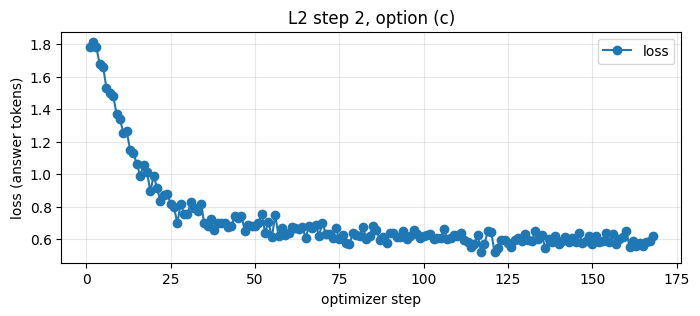

- Steps: 168 of 211 (not complete: run the notebook again to continue)
- Examples: 53,838 (full run: 53,838, {'train': 53032, 'options': 806}); by task {'Disaster Bearing Bodies Recognition': 7381, 'Building Damage Counting': 14332, 'Road Damage Counting': 7227, 'disaster caption': 7381, 'Disaster Type Recognition': 1543, 'disaster restoration advice': 7380, 'Disaster Scene Recognition': 6742, 'relational reasoning': 1852}
- The new 7B's answers used: 1,079
- Longest example: 1,852 tokens; peak GPU memory, process 0: 5.94 GB
- Losses: [1.784, 1.812, 1.782, 1.676, 1.661, 1.529, 1.501, 1.482, 1.372, 1.338, 1.256, 1.264, 1.15, 1.129, 1.062, 0.99, 1.06, 1.015, 0.894, 0.991, 0.916, 0.834, 0.875, 0.882, 0.818, 0.797, 0.7, 0.819, 0.755, 0.755, 0.83, 0.79, 0.772, 0.818, 0.698, 0.684, 0.722, 0.657, 0.697, 0.7, 0.701, 0.677, 0.679, 0.745, 0.729, 0.742, 0.653, 0.687, 0.682, 0.685, 0.7, 0.759, 0.639, 0.709, 0.612, 0.749, 0.618, 0.667, 0.629, 0.641, 0.676, 0.669, 0.662, 0.677, 0.61, 0.68, 0.67, 0.6

In [5]:
# ── Cell 5: What the run did: the losses, memory and time, and a README ──
import matplotlib.pyplot as plt

S_PATH = WORK / ("train_summary_smoke.json" if SMOKE_TEST else "train_summary.json")
assert S_PATH.exists(), f"No {S_PATH.name}: the training stopped early; read Cell 4's output"
S = json.loads(S_PATH.read_text(encoding="utf-8"))
steps_ = [e for e in S["log_history"] if "loss" in e]
if steps_:
    plt.figure(figsize=(8, 3))
    plt.plot([e["step"] for e in steps_], [e["loss"] for e in steps_], marker="o", label="loss")
    if any("soft_loss" in e for e in steps_):
        plt.plot([e["step"] for e in steps_ if "soft_loss" in e], [e["soft_loss"] for e in steps_ if "soft_loss" in e], label="soft loss")
        plt.plot([e["step"] for e in steps_], [e.get("label_loss") for e in steps_], label="label loss")
    plt.xlabel("optimizer step")
    plt.ylabel("loss (answer tokens)")
    plt.title(f"L2 step 2, option ({MODE})" + (" (smoke test)" if SMOKE_TEST else ""))
    plt.legend()
    plt.grid(alpha=0.3)
    plt.savefig(WORK / "loss_curve.png", dpi=120, bbox_inches="tight")
    plt.show()

lines = [
    f"- Steps: {S['global_step']} of {S['max_steps']} ({'complete' if S['complete'] else 'not complete: run the notebook again to continue'})",
    f"- Examples: {S['examples']:,} (full run: {S['full_examples']:,}, {S['by_kind']}); by task {S['by_task']}",
    (f"- Soft labels: {S['soft_labels']:,}; soft-loss tokens this session {S['soft_tokens_this_session']:,}, misaligned "
     f"{S['misaligned_tokens_this_session']}" if MODE == "b" else f"- The new 7B's answers used: {S['teacher_answers']:,}"),
    f"- Longest example: {S['longest_tokens']:,} tokens; peak GPU memory, process 0: {S['peak_gpu_memory_gb_process0']} GB",
    f"- Losses: {[round(e['loss'], 3) for e in steps_]}",
    f"- Last step: {S['seconds_per_example']} s per example on both GPUs; projected for all {S['full_examples']:,} examples: "
    f"{S['projected_full_hours']} h",
    f"- Versions: {S['versions']}",
]
if SMOKE_TEST:
    lines += ["", "How to read the smoke test:",
              "- Loss: about 0.4-1.2 is the 7B's first training level on answer tokens. Above 3, the labels are misaligned.",
              "- Peak memory under about 14 GB leaves room on a T4 (15 GB).",
              "- Over 10.5 projected hours, the full run takes two or more sessions (it continues from Hugging Face)."]
print("\n".join(lines))
(WORK / "README.md").write_text("\n".join([
    f"# L2 step 2 (with step 2b's fix): the 3B, option ({MODE}){' (SMOKE TEST)' if SMOKE_TEST else ''}", "",
    f"`{CFG['base_model']}` held in 4-bit, a new LoRA adapter (rank 64, alpha 16) on the language model, the 7B's recipe "
    f"(lr 2e-4, cosine, global batch {2 * CFG['grad_accum']}, one epoch), images at most 768 x 28 x 28 pixels, the 501 held-out "
    "after-photos left out. " + ("(b): the label loss plus the match to the 7B's top-20 spread, 0.5 each, on the checkable entries."
                                 if MODE == "b" else "(c): L2 step 1's data plus L2 step 1c's options examples, label loss only."), "",
    *lines, "",
    f"Checkpoints: `{CFG['adapter_repo']}/{CFG['hub_dir']}`. Finished adapter: `{CFG['adapter_repo']}/{CFG['final_dir']}`.",
]), encoding="utf-8")
print(f"\n✓ Wrote README.md{' and loss_curve.png' if steps_ else ''} to {WORK}")